In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

cleaned_counts_layer = "raw_cleaned"
purified_counts_layer = "split_purified_counts"
purified_condition_label = "split"
condition_order = ["uncorrected", "cleaned_expression", purified_condition_label]
condition_palette = {
    "uncorrected": "#8c8c8c",
    "cleaned_expression": "#1f77b4",
    purified_condition_label: "#b937ec",
}

st_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/spatial_adata/heimdall_inference/GSM9509174_breast_breast_B1_B1_3_rctd_annotated_val_med_with_admix_probs.h5ad')

In [2]:
st_data.obs['x_centroid'].max()

6750.7734375

In [3]:
import sys
sys.path.append('/home/jwinchel/Syndri/eval/')
from neighbor_prediction import add_log_normalized_layer, run_specificity_contamination_assessment

/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/home/jwinchel/miniconda3/envs/rctd/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: 

In [4]:
from scipy import sparse

X = st_data.X.copy()
mask = st_data.layers["admix_probs"] > 0.5

if sparse.issparse(X):
    X = X.tolil()
    X[mask] = 0
    X = X.tocsr()
    X.eliminate_zeros()
else:
    X[mask] = 0

st_data.layers[cleaned_counts_layer] = X


In [5]:
st_data.layers['admix_probs']

<108069x277 sparse matrix of type '<class 'numpy.float32'>'
	with 5400643 stored elements in Compressed Sparse Row format>

In [6]:
test_data = st_data.copy()
test_data.obsm['spatial'] = test_data.obs[['x_centroid','y_centroid']].values

In [7]:
test_data = add_log_normalized_layer(test_data, counts_layer=None, out_layer="lognorm")
test_data = add_log_normalized_layer(test_data, counts_layer=cleaned_counts_layer, out_layer="lognorm_cleaned")
test_data = add_log_normalized_layer(test_data, counts_layer=purified_counts_layer, out_layer="lognorm_purified")

specificity_layers = {
    "uncorrected": "lognorm",
    "cleaned_expression": "lognorm_cleaned",
    purified_condition_label: "lognorm_purified",
}
all_specificity_results = []

for condition, layer in specificity_layers.items():
    res, coef, markers = run_specificity_contamination_assessment(
        test_data,
        sample_key="batch",
        cell_type_key="rctd_first_type",
        coord_key="spatial",
        layer=layer,
        radius_um=15.0,
        top_n=6,
        min_cells_per_label=100,
        random_state=0,
    )

    res["condition"] = condition
    all_specificity_results.append(res)

specificity_comparison = pd.concat(all_specificity_results, ignore_index=True)
comparison = specificity_comparison


In [8]:
markers

,sample,cell_type,marker_rank,gene
0,st,fibroblast of lung,1,ENSG00000139329
1,st,fibroblast of lung,2,ENSG00000087245
2,st,fibroblast of lung,3,ENSG00000133110
3,st,fibroblast of lung,4,ENSG00000091986
4,st,fibroblast of lung,5,ENSG00000106483
...,...,...,...,...
85,st,natural killer cell,2,ENSG00000121966
86,st,natural killer cell,3,ENSG00000134539
87,st,natural killer cell,4,ENSG00000271503
88,st,natural killer cell,5,ENSG00000168685


In [9]:
ensembl_dict = st_data.var[['id','name']].values
ensembl_dict = {x[0]:x[1] for x in ensembl_dict}
markers['gene_symbol'] = markers['gene'].map(ensembl_dict)

In [11]:
specificity_comparison[
    (specificity_comparison["target_cell_type_i"].str.contains("T", na=False))
    & (specificity_comparison["contaminating_cell_type_j"].str.contains("malignant", na=False))
]

,sample,target_cell_type_i,contaminating_cell_type_j,n_target_cells_total,n_proximal_to_j,n_distal_to_j,n_fit_cells,top_n,marker_overlap_n,marker_overlap_frac,overlap_genes,top_coef_genes,contaminating_type_markers,zscore_mode,condition
51,st,natural T-regulatory cell,malignant cell,781,160,621,781,6,1,0.166667,[ENSG00000183569],"[ENSG00000183569, ENSG00000196091, ENSG0000008...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,uncorrected
112,st,cytotoxic T cell,malignant cell,2200,255,1945,2200,6,1,0.166667,[ENSG00000183569],"[ENSG00000150045, ENSG00000183569, ENSG0000017...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,uncorrected
129,st,"CD4-positive, alpha-beta memory T cell",malignant cell,890,103,787,890,6,1,0.166667,[ENSG00000183569],"[ENSG00000183569, ENSG00000121270, ENSG0000011...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,uncorrected
197,st,natural T-regulatory cell,malignant cell,781,160,621,781,6,1,0.166667,[ENSG00000135480],"[ENSG00000099194, ENSG00000121270, ENSG0000010...","[ENSG00000076554, ENSG00000135480, ENSG0000016...",exact,cleaned_expression
258,st,cytotoxic T cell,malignant cell,2200,255,1945,2200,6,1,0.166667,[ENSG00000169710],"[ENSG00000112799, ENSG00000091986, ENSG0000016...","[ENSG00000076554, ENSG00000135480, ENSG0000016...",exact,cleaned_expression
275,st,"CD4-positive, alpha-beta memory T cell",malignant cell,890,103,787,890,6,2,0.333333,"[ENSG00000183569, ENSG00000135480]","[ENSG00000121270, ENSG00000110848, ENSG0000018...","[ENSG00000076554, ENSG00000135480, ENSG0000016...",exact,cleaned_expression
343,st,natural T-regulatory cell,malignant cell,781,160,621,781,6,2,0.333333,"[ENSG00000183569, ENSG00000135480]","[ENSG00000183569, ENSG00000087245, ENSG0000010...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,split
404,st,cytotoxic T cell,malignant cell,2200,255,1945,2200,6,1,0.166667,[ENSG00000183569],"[ENSG00000173269, ENSG00000168497, ENSG0000016...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,split
421,st,"CD4-positive, alpha-beta memory T cell",malignant cell,890,103,787,890,6,1,0.166667,[ENSG00000183569],"[ENSG00000121270, ENSG00000183569, ENSG0000011...","[ENSG00000135480, ENSG00000148513, ENSG0000016...",exact,split


In [10]:
specificity_effect = (
    specificity_comparison
    .groupby(["condition", "target_cell_type_i", "contaminating_cell_type_j"])
    ["marker_overlap_n"]
    .mean()
    .reset_index()
    .pivot(
        index=["target_cell_type_i", "contaminating_cell_type_j"],
        columns="condition",
        values="marker_overlap_n",
    )
    .reset_index()
)

specificity_effect["delta_cleaned_minus_uncorrected"] = (
    specificity_effect["cleaned_expression"] - specificity_effect["uncorrected"]
)
specificity_effect["delta_purified_minus_uncorrected"] = (
    specificity_effect[purified_condition_label] - specificity_effect["uncorrected"]
)
specificity_effect["delta_purified_minus_cleaned"] = (
    specificity_effect[purified_condition_label] - specificity_effect["cleaned_expression"]
)

tcell_specificity_effect = specificity_effect[
    specificity_effect["target_cell_type_i"].str.contains("T", na=False)
].sort_values("delta_purified_minus_cleaned")

tcell_specificity_effect


condition,target_cell_type_i,contaminating_cell_type_j,cleaned_expression,split,uncorrected,delta_cleaned_minus_uncorrected,delta_purified_minus_uncorrected,delta_purified_minus_cleaned
2,"CD4-positive, alpha-beta memory T cell",cytotoxic T cell,2.0,1.0,2.0,0.0,-1.0,-1.0
5,"CD4-positive, alpha-beta memory T cell",malignant cell,2.0,1.0,1.0,1.0,0.0,-1.0
41,cytotoxic T cell,plasmacytoid dendritic cell,2.0,1.0,2.0,0.0,-1.0,-1.0
1,"CD4-positive, alpha-beta memory T cell",classical monocyte,0.0,0.0,0.0,0.0,0.0,0.0
6,"CD4-positive, alpha-beta memory T cell",natural T-regulatory cell,0.0,0.0,0.0,0.0,0.0,0.0
4,"CD4-positive, alpha-beta memory T cell",macrophage,1.0,1.0,1.0,0.0,0.0,0.0
7,"CD4-positive, alpha-beta memory T cell",natural killer cell,0.0,0.0,0.0,0.0,0.0,0.0
0,"CD4-positive, alpha-beta memory T cell",capillary endothelial cell,0.0,0.0,1.0,-1.0,-1.0,0.0
36,cytotoxic T cell,malignant cell,1.0,1.0,1.0,0.0,0.0,0.0
31,cytotoxic T cell,"CD4-positive, alpha-beta memory T cell",1.0,1.0,1.0,0.0,0.0,0.0


/tmp/ipykernel_163223/2767477309.py:8: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_163223/2767477309.py:27: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


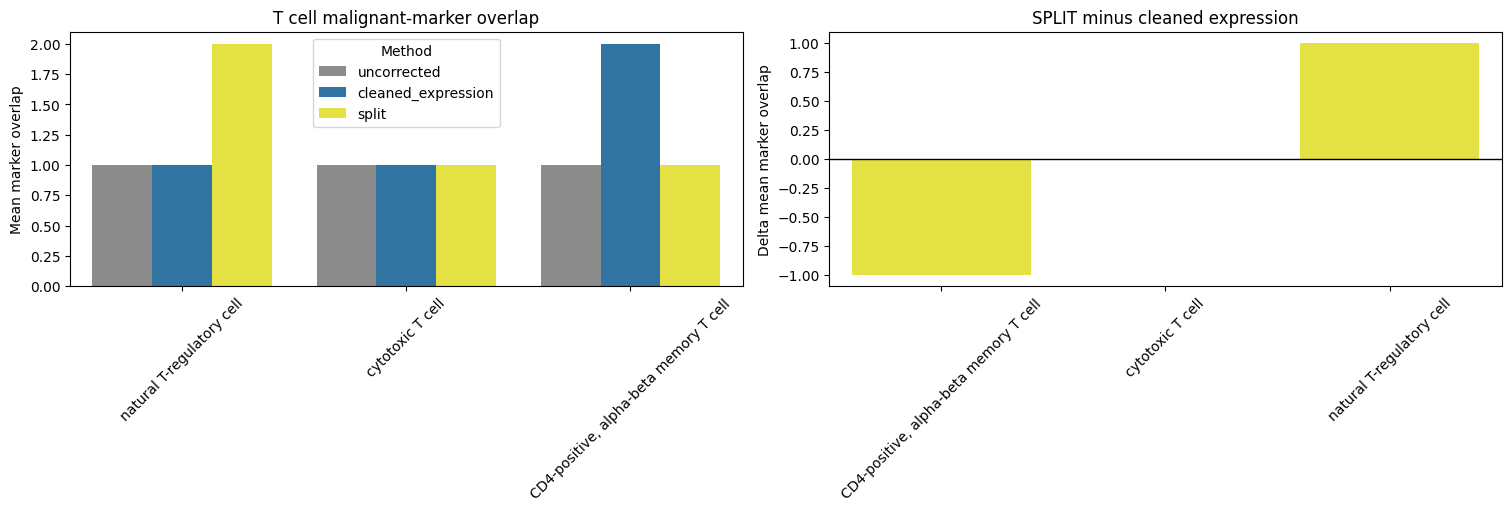

In [11]:
tcell_malignant_specificity = specificity_comparison[
    (specificity_comparison["target_cell_type_i"].str.contains("T", na=False))
    & (specificity_comparison["contaminating_cell_type_j"] == "malignant cell")
].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

sns.barplot(
    data=tcell_malignant_specificity,
    x="target_cell_type_i",
    y="marker_overlap_n",
    hue="condition",
    hue_order=condition_order,
    palette=condition_palette,
    ci=None,
    ax=axes[0],
)
axes[0].set_title("T cell malignant-marker overlap")
axes[0].set_xlabel("")
axes[0].set_ylabel("Mean marker overlap")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Method")

tcell_malignant_effect = tcell_specificity_effect[
    tcell_specificity_effect["contaminating_cell_type_j"] == "malignant cell"
].copy()
sns.barplot(
    data=tcell_malignant_effect,
    x="target_cell_type_i",
    y="delta_purified_minus_cleaned",
    color=condition_palette[purified_condition_label],
    ci=None,
    ax=axes[1],
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("SPLIT minus cleaned expression")
axes[1].set_xlabel("")
axes[1].set_ylabel("Delta mean marker overlap")
axes[1].tick_params(axis="x", rotation=45)

plt.show()


In [12]:
sc_data = ad.read_h5ad('/compute/oven-0-13/jwinchel/split_spatial_chromium/breast_cancer_chromium_integrated.h5ad')
sc_data.obs['cell_type'].value_counts()

cell_type
malignant cell                            4478
plasma cell                                709
fibroblast of lung                         703
capillary endothelial cell                 528
smooth muscle cell                         526
cytotoxic T cell                           498
fibroblast of breast                       448
classical monocyte                         349
natural T-regulatory cell                  286
macrophage                                 215
CD4-positive, alpha-beta memory T cell     200
pericyte                                   178
mast cell                                  122
natural killer cell                        111
plasmacytoid dendritic cell                 65
Name: count, dtype: int64

In [17]:
# cosine similarity of log-normalized pseudo-bulk xenium to chromium reference
from pseudobulk_reference_similarity import cell_type_pseudobulk_cosine_similarity

pseudobulk_layers = {
    "uncorrected": None,
    "cleaned_expression": cleaned_counts_layer,
    purified_condition_label: purified_counts_layer,
}
all_sims = []

for condition, layer in pseudobulk_layers.items():
    sims, _, _ = cell_type_pseudobulk_cosine_similarity(
        spatial_adata=st_data,
        chromium_adata=sc_data,
        spatial_cell_type_key="rctd_first_type",
        chromium_cell_type_key="cell_type",
        spatial_layer=layer,
        chromium_layer=None,
        target_sum=1e4,
        min_cells_spatial=20,
        min_cells_chromium=20,
    )

    sims["condition"] = condition
    all_sims.append(sims)

pseudobulk_comparison = pd.concat(all_sims, ignore_index=True)
comparison = pseudobulk_comparison


In [18]:
pseudobulk_comparison


,spatial_cell_type,chromium_cell_type,cosine_similarity,n_spatial_cells,n_chromium_cells,n_shared_genes,condition
0,fibroblast of lung,fibroblast of lung,0.967359,49482,703,277,uncorrected
1,plasma cell,plasma cell,0.958315,4720,709,277,uncorrected
2,pericyte,pericyte,0.957787,2840,178,277,uncorrected
3,smooth muscle cell,smooth muscle cell,0.952698,3033,526,277,uncorrected
4,capillary endothelial cell,capillary endothelial cell,0.938932,4089,528,277,uncorrected
5,mast cell,mast cell,0.932677,636,122,277,uncorrected
6,malignant cell,malignant cell,0.930511,32240,4478,277,uncorrected
7,macrophage,macrophage,0.920592,4143,215,277,uncorrected
8,plasmacytoid dendritic cell,plasmacytoid dendritic cell,0.913776,1053,65,277,uncorrected
9,fibroblast of breast,fibroblast of breast,0.911255,494,448,277,uncorrected


In [19]:
pseudobulk_effect = (
    pseudobulk_comparison
    .pivot(
        index=["spatial_cell_type", "chromium_cell_type"],
        columns="condition",
        values="cosine_similarity",
    )
    .reset_index()
)

pseudobulk_effect["delta_cleaned_minus_uncorrected"] = (
    pseudobulk_effect["cleaned_expression"] - pseudobulk_effect["uncorrected"]
)
pseudobulk_effect["delta_purified_minus_uncorrected"] = (
    pseudobulk_effect[purified_condition_label] - pseudobulk_effect["uncorrected"]
)
pseudobulk_effect["delta_purified_minus_cleaned"] = (
    pseudobulk_effect[purified_condition_label] - pseudobulk_effect["cleaned_expression"]
)

pseudobulk_effect = pseudobulk_effect.sort_values("delta_purified_minus_cleaned", ascending=False)
pseudobulk_effect[
    pseudobulk_effect["spatial_cell_type"].str.contains("T", na=False)
    & (pseudobulk_effect["spatial_cell_type"] == pseudobulk_effect["chromium_cell_type"])
]


condition,spatial_cell_type,chromium_cell_type,cleaned_expression,split,uncorrected,delta_cleaned_minus_uncorrected,delta_purified_minus_uncorrected,delta_purified_minus_cleaned
0,"CD4-positive, alpha-beta memory T cell","CD4-positive, alpha-beta memory T cell",0.893121,0.972025,0.872703,0.020417,0.099321,0.078904
9,natural T-regulatory cell,natural T-regulatory cell,0.907369,0.971051,0.891190,0.016179,0.079860,0.063682
3,cytotoxic T cell,cytotoxic T cell,0.918146,0.968075,0.896614,0.021532,0.071461,0.049929


/tmp/ipykernel_163223/3425360191.py:14: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_163223/3425360191.py:30: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(


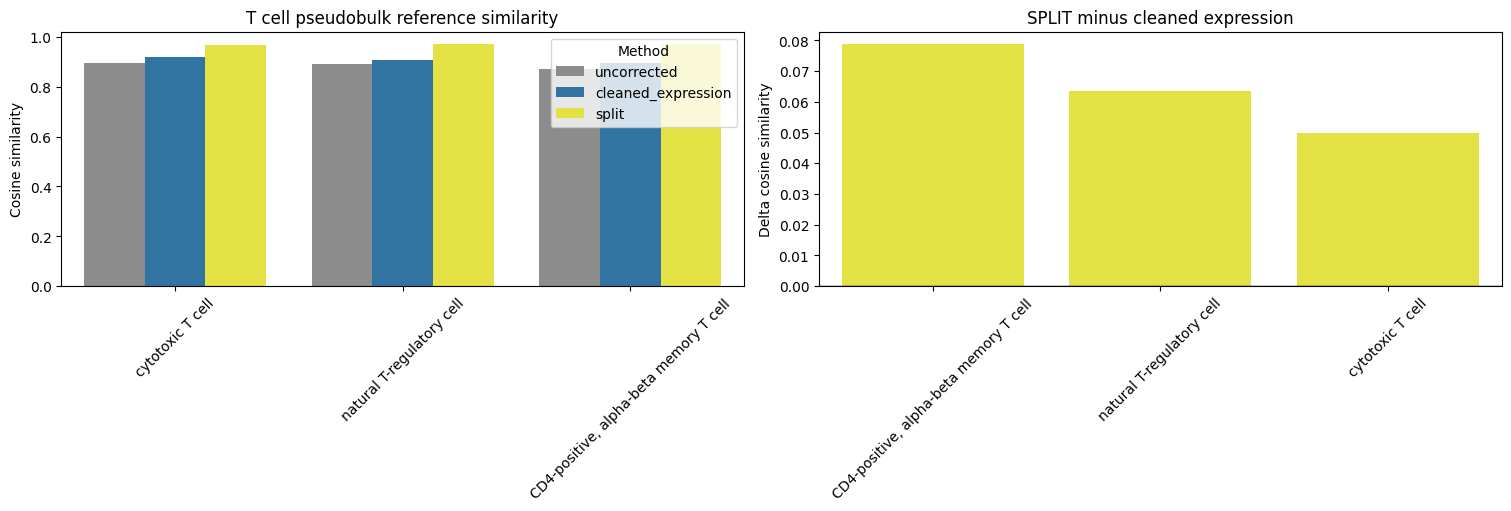

In [20]:
pseudobulk_same_type = pseudobulk_comparison[
    pseudobulk_comparison["spatial_cell_type"] == pseudobulk_comparison["chromium_cell_type"]
].copy()
tcell_pseudobulk = pseudobulk_same_type[
    pseudobulk_same_type["spatial_cell_type"].str.contains("T", na=False)
].copy()
tcell_pseudobulk_effect = pseudobulk_effect[
    pseudobulk_effect["spatial_cell_type"].str.contains("T", na=False)
    & (pseudobulk_effect["spatial_cell_type"] == pseudobulk_effect["chromium_cell_type"])
].copy()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

sns.barplot(
    data=tcell_pseudobulk,
    x="spatial_cell_type",
    y="cosine_similarity",
    hue="condition",
    hue_order=condition_order,
    palette=condition_palette,
    ci=None,
    ax=axes[0],
)
axes[0].set_title("T cell pseudobulk reference similarity")
axes[0].set_xlabel("")
axes[0].set_ylabel("Cosine similarity")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Method")

sns.barplot(
    data=tcell_pseudobulk_effect,
    x="spatial_cell_type",
    y="delta_purified_minus_cleaned",
    color=condition_palette[purified_condition_label],
    ci=None,
    ax=axes[1],
)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("SPLIT minus cleaned expression")
axes[1].set_xlabel("")
axes[1].set_ylabel("Delta cosine similarity")
axes[1].tick_params(axis="x", rotation=45)

plt.show()


In [4]:
st_data.obs['rctd_spot_class'].unique()

['doublet_uncertain', 'doublet_certain', 'singlet', 'reject', 'rctd_filtered']
Categories (5, object): ['doublet_certain', 'doublet_uncertain', 'rctd_filtered', 'reject', 'singlet']

In [5]:
import scanpy as sc
st_test = st_data.copy()

sc.pp.log1p(st_test)
sc.pp.pca(st_test)
sc.pp.neighbors(st_test,n_neighbors=50)
sc.tl.umap(st_test)

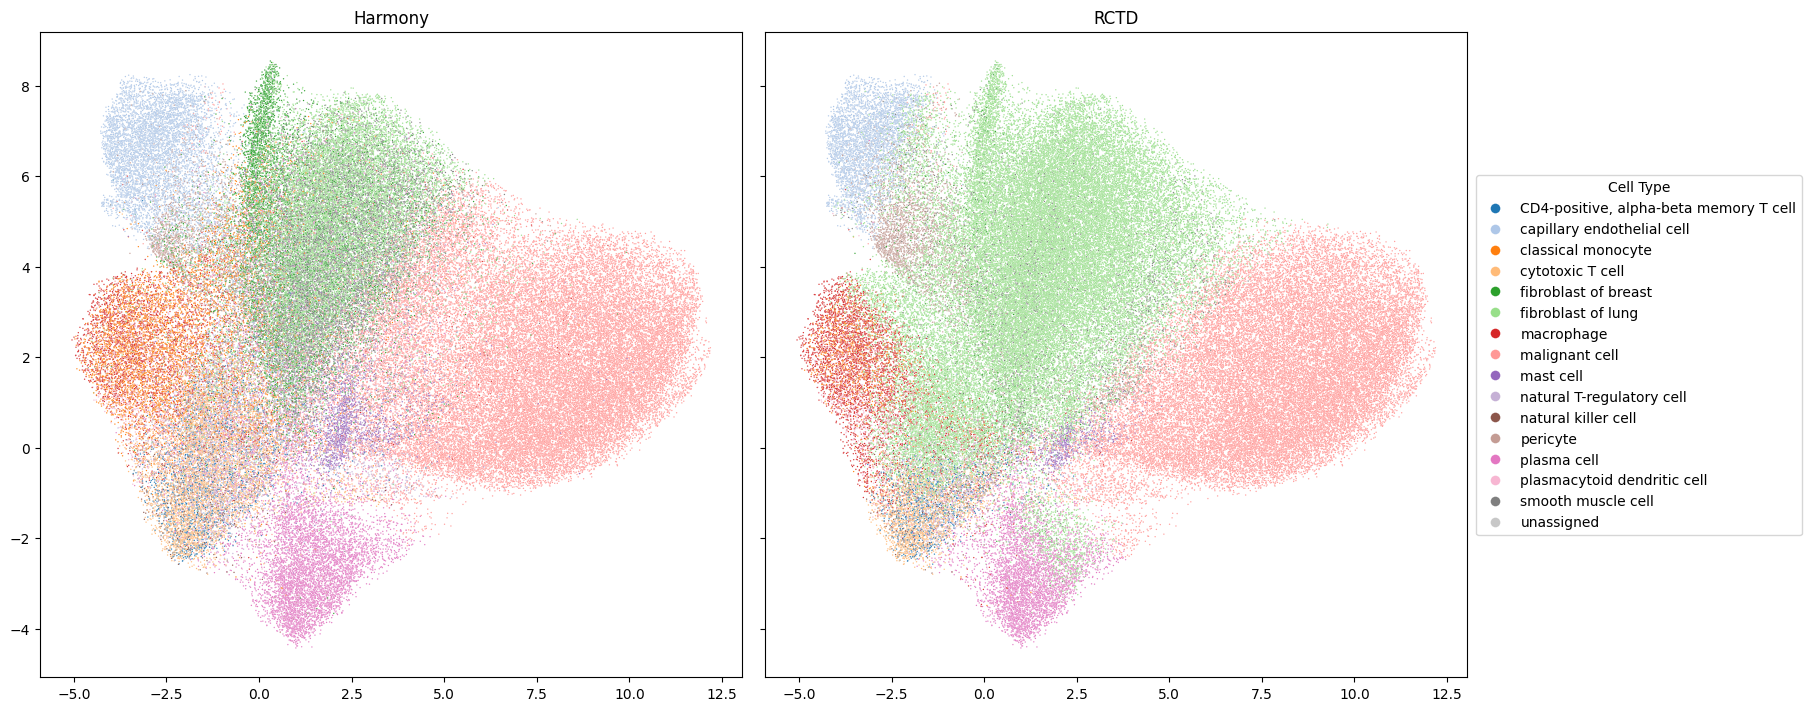

In [16]:
import seaborn as sns
fig,axes = plt.subplots(ncols=2,figsize=(18,7),layout="constrained",sharex=True,sharey=True)
ax = axes[0]
ax = sns.scatterplot(x=st_test.obsm['X_umap'][:,0],y=st_test.obsm['X_umap'][:,1],hue=st_test.obs['harmony_cell_type'],s=1,ax=ax,palette='tab20')
# ax.legend(bbox_to_anchor=(1,1.05),markerscale=7,show=False)
ax.legend().set_visible(False)
ax.set_title("Harmony")
ax = axes[1]
ax = sns.scatterplot(x=st_test.obsm['X_umap'][:,0],y=st_test.obsm['X_umap'][:,1],hue=st_test.obs['rctd_first_type'],s=1,ax=ax,palette='tab20')
# ax.legend(bbox_to_anchor=(1,1.05),markerscale=7)
ax.legend().set_visible(False)
ax.set_title("RCTD")

# 4. Gather handles and labels automatically from all axes
# Combine handles and labels
handles, labels = [], []
for ax in fig.axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h)
            labels.append(l)

# Add a single legend to the entire figure
fig.legend(handles, labels, loc='outside center right',markerscale=7,title="Cell Type")

# 5. Create a single shared figure legend
# fig.legend(handles, labels, loc="upper center", ncol=2)

In [35]:
st_test.obs['harmony_cell_type'].value_counts(),st_test.obs['rctd_first_type'].value_counts()

(harmony_cell_type
 malignant cell                            37022
 fibroblast of lung                        14446
 smooth muscle cell                         9260
 plasma cell                                8002
 capillary endothelial cell                 6795
 fibroblast of breast                       6696
 classical monocyte                         5734
 cytotoxic T cell                           5107
 macrophage                                 3215
 natural T-regulatory cell                  3160
 pericyte                                   2524
 mast cell                                  2038
 CD4-positive, alpha-beta memory T cell     1692
 plasmacytoid dendritic cell                1380
 natural killer cell                         998
 Name: count, dtype: int64,
 rctd_first_type
 fibroblast of lung                        49482
 malignant cell                            32240
 plasma cell                                4720
 macrophage                                 4143
 capi